In [40]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter


In [63]:
sales_path = r"C:\Users\abdo2\Desktop\Projects\Global Fashion Retail-dashboard\backend\data\transactions.csv"
products_path = r"C:\Users\abdo2\Desktop\Projects\Global Fashion Retail-dashboard\backend\data\products.csv"
sales_df = pd.read_csv(sales_path)
products_df = pd.read_csv(products_path)
merged_df  = sales_df.merge(
    products_df,
    on="Product ID",
    how="left"
)

In [ ]:
sales_df.head(100)


,Invoice ID,Line,Customer ID,Product ID,Size,Color,Unit Price,Quantity,Date,Discount,Line Total,Store ID,Employee ID,Currency,Currency Symbol,SKU,Transaction Type,Payment Method,Invoice Total
0,INV-US-001-03558761,1,47162,485,M,NaN,80.5,1,2023-01-01 15:42:00,0.0,80.5,1,7,USD,$,MASU485-M-,Sale,Cash,126.7
1,INV-US-001-03558761,2,47162,2779,G,NaN,31.5,1,2023-01-01 15:42:00,0.4,18.9,1,7,USD,$,CHCO2779-G-,Sale,Cash,126.7
2,INV-US-001-03558761,3,47162,64,M,NEUTRAL,45.5,1,2023-01-01 15:42:00,0.4,27.3,1,7,USD,$,MACO64-M-NEUTRAL,Sale,Cash,126.7
3,INV-US-001-03558762,1,10142,131,M,BLUE,70.0,1,2023-01-01 20:04:00,0.4,42.0,1,6,USD,$,FECO131-M-BLUE,Sale,Cash,77.0
4,INV-US-001-03558762,2,10142,716,L,WHITE,26.0,1,2023-01-01 20:04:00,0.0,26.0,1,6,USD,$,MAT-716-L-WHITE,Sale,Cash,77.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,INV-US-001-03558832,2,41377,1027,M,NEUTRAL,41.0,1,2023-01-01 18:36:00,0.4,24.6,1,6,USD,$,MASW1027-M-NEUTRAL,Sale,Credit Card,105.1
96,INV-US-001-03558833,1,61446,1757,XXL,NaN,17.0,1,2023-01-01 10:45:00,0.0,17.0,1,6,USD,$,MASH1757-XXL-,Sale,Credit Card,17.0
97,INV-US-001-03558834,1,41637,1817,M,BURGUNDY,43.0,1,2023-01-01 19:43:00,0.4,25.8,1,13,USD,$,CHCO1817-M-BURGUNDY,Sale,Credit Card,25.8
98,INV-US-001-03558835,1,77385,2482,M,NaN,40.0,3,2023-01-01 18:57:00,0.4,72.0,1,11,USD,$,MACO2482-M-,Sale,Credit Card,72.0


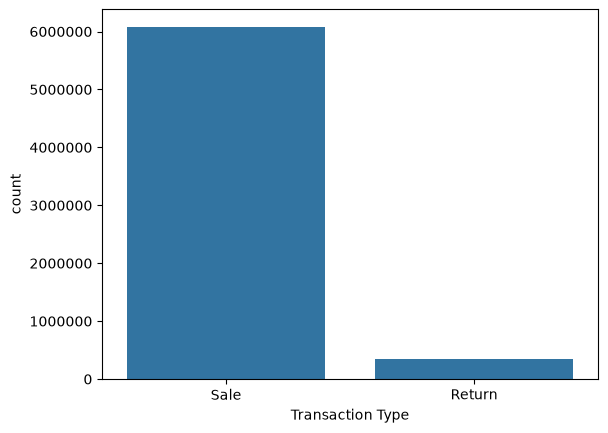

In [ ]:
#Transaction Type Count Plot
# Transaction_type_count = df["Transaction Type"].value_counts()
# data = {
#     "Transaction Type":Transaction_type_count.index.tolist(),
#     "Count":Transaction_type_count.values.tolist()
# }
count_plt = sns.countplot(data=sales_df, x="Transaction Type")
count_plt.yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
count_plt.ticklabel_format(style="plain", axis="y")
plt.show()

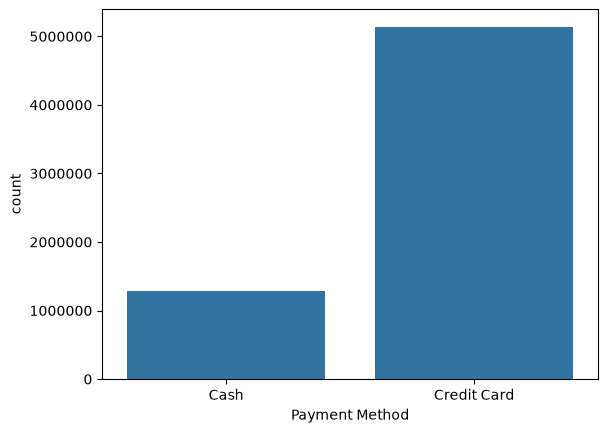

In [ ]:
#Payment Method type Count plot
# payment_method_count = df["Payment Method"].value_counts()
# data = {
#     "Payment Methods":payment_method_count.index.tolist(),
#     "Count":payment_method_count.values.tolist()
# }
count_plt = sns.countplot(data=sales_df, x="Payment Method")
count_plt.yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
count_plt.ticklabel_format(style="plain", axis="y")
plt.show()

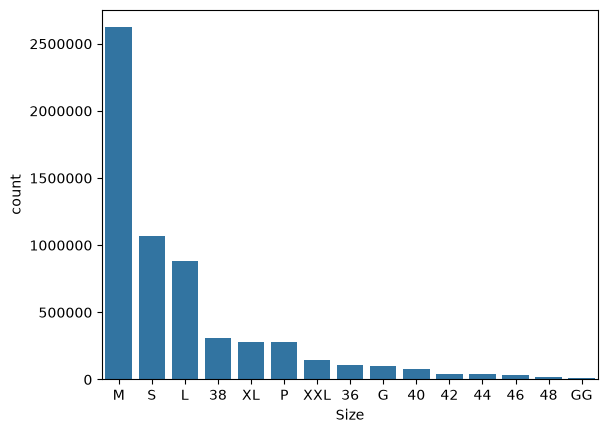

In [ ]:
#Size plot
order = sales_df["Size"].value_counts().index
# size_count = df["Size"].value_counts()
# data = {
#     "categories": size_count.index.tolist(),
#     "counts": size_count.values.tolist()
# }

count_plt = sns.countplot(data=sales_df, x="Size",order=order)

count_plt.yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
count_plt.ticklabel_format(style="plain", axis="y")
plt.show()

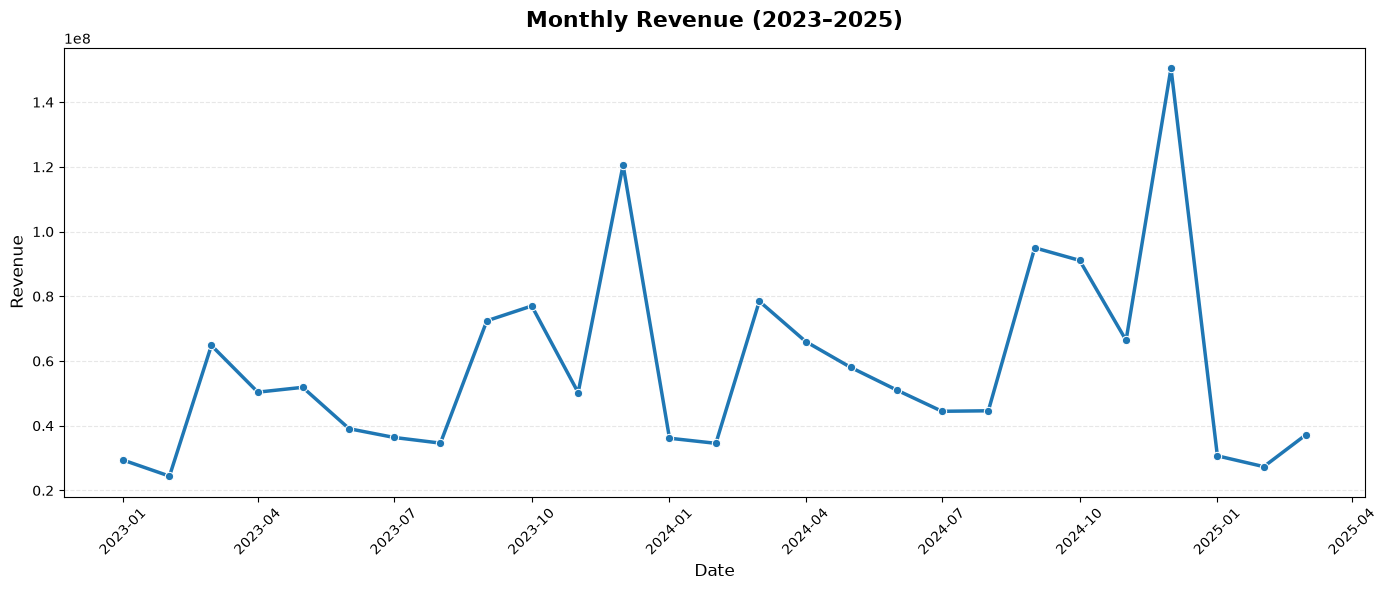

In [ ]:

#Monthly Revenue
sales_df["Date"] = pd.to_datetime(sales_df["Date"])

df = sales_df[
    (sales_df["Date"].dt.year >= 2023) &
    (sales_df["Date"].dt.year <= 2025)
]

monthly_revenue = df.groupby(
    df["Date"].dt.to_period("M")
)["Invoice Total"].sum()

monthly_revenue.index = monthly_revenue.index.to_timestamp()
# data = {
#     "monthly_revenue_data":monthly_revenue.index,
#     "revenue":monthly_revenue.values
# }
plt.figure(figsize=(14, 6))

sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker="o",
    linewidth=2.5
)

plt.title(
    "Monthly Revenue (2023–2025)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Date", fontsize=12)
plt.ylabel("Revenue", fontsize=12)

plt.xticks(rotation=45)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)



plt.tight_layout()
plt.show()

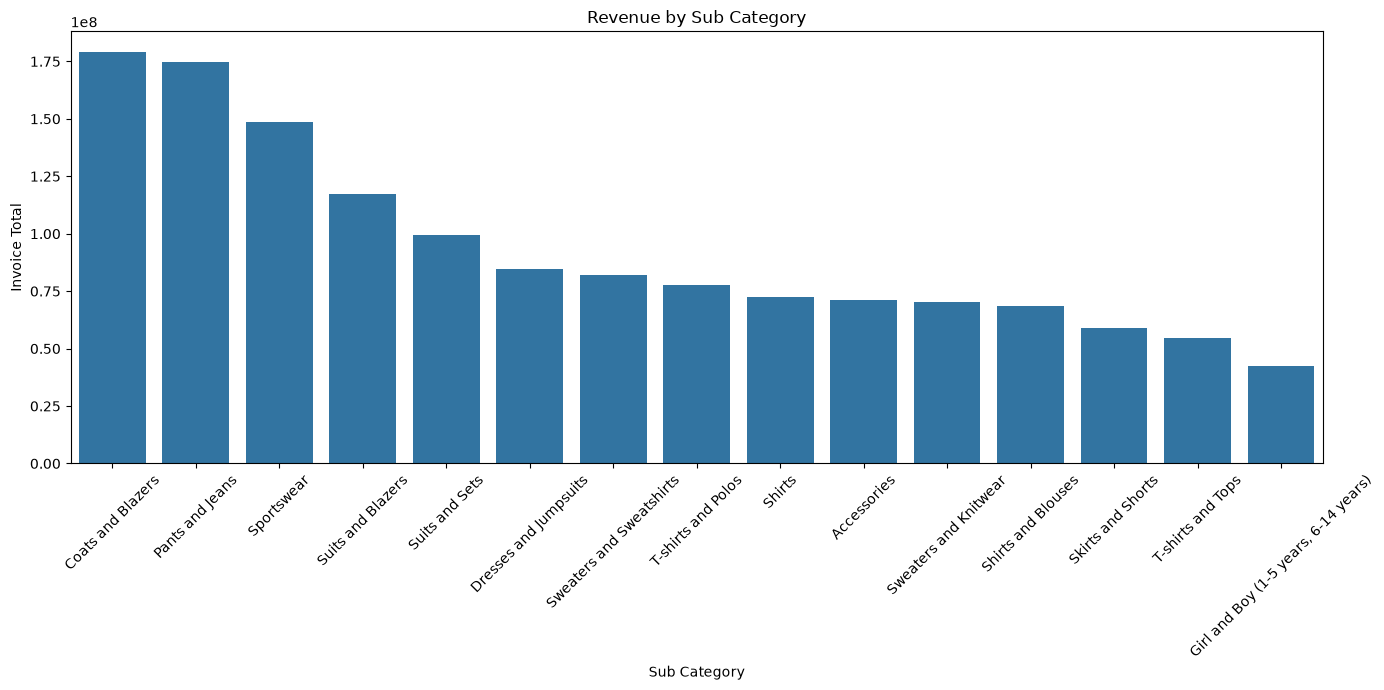

In [ ]:
#Top 15 best sub-catagories by revenue
sales_df["Product ID"] = sales_df["Product ID"].astype(str)
products_df["Product ID"] = products_df["Product ID"].astype(str)


top_15 = (
    merged_df.groupby("Sub Category")["Invoice Total"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)
plt.figure(figsize=(14, 7))

sns.barplot(
    data=top_15,
    x="Sub Category",
    y="Invoice Total"
)

plt.xlabel("Sub Category")
plt.ylabel("Invoice Total")
plt.title("Revenue by Sub Category")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

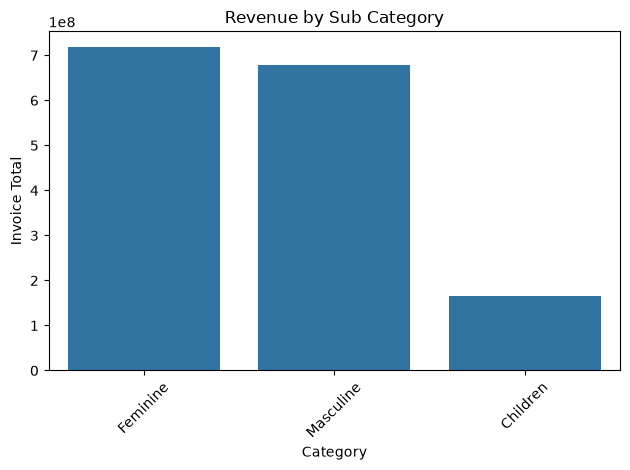

In [ ]:
#Most Selling Categories
catagories_by_revenue = merged_df.groupby("Category")["Invoice Total"].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=catagories_by_revenue,x="Category",y="Invoice Total")
plt.xlabel("Category")
plt.ylabel("Invoice Total")
plt.title("Revenue by Sub Category")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

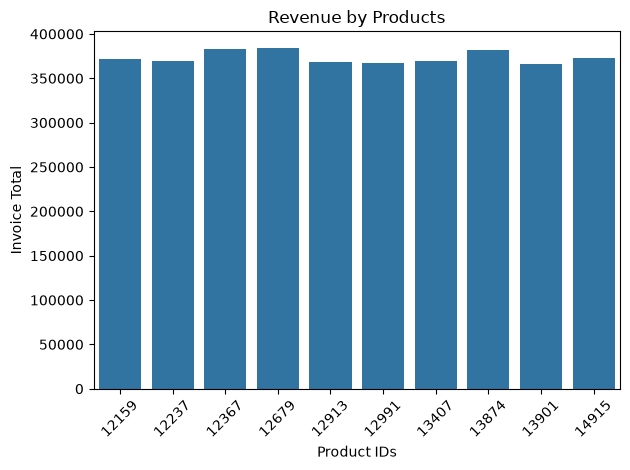

In [72]:
#Top 10 products by revenue
products_by_revenue = merged_df.groupby("Product ID")["Invoice Total"].sum().sort_values(ascending=False).head(10).reset_index()
sns.barplot(data=products_by_revenue,x="Product ID",y="Invoice Total")
plt.xlabel("Product IDs")
plt.ylabel("Invoice Total")
plt.title("Revenue by Products")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()